# Step 8: Machine learning comparison

In notebook 3 I used a **linear regression**, which assumes each operational measure has a straight-line relationship with satisfaction. Machine learning models can pick up curves and interactions by themselves, so I wanted to see whether they do any better. I had two questions:

1. **Prediction:** do machine learning models predict a landlord's overall satisfaction better than my notebook 3 regression?
2. **Classification:** can I flag landlords at risk of **bottom-quartile** satisfaction from their operational data alone, and which landlords does it miss?

**The models I'm trying**

| Model | How it works, as I understand it |
| --- | --- |
| **Linear regression** | One straight-line effect per input, all added together (notebook 3) |
| **Random forest** | Grows hundreds of **decision trees**, each one a flowchart of yes/no questions ("are stage 2 complaints above 12 per 1,000?"), each trained on a random sample of landlords. The forest's prediction is the average of all the trees |
| **Gradient boosting** | Builds small trees one after another, each one trying to fix the mistakes of the trees before it |
| **Logistic regression** | Like linear regression, but predicts a **probability** (0 to 1) of a yes/no outcome |

The risk with flexible models is **overfitting**: learning the quirks of these particular landlords that don't apply anywhere else. With fewer than 200 landlords that's a real worry, so I only ever compare models on landlords they **haven't seen** (cross-validation).

This notebook only needs the TSM file.

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
# Lots of scikit-learn this time. First, the cross-validation tools.
from sklearn.model_selection import (RepeatedKFold, RepeatedStratifiedKFold, KFold,
                                     StratifiedKFold, cross_validate, cross_val_predict)
# Tools for preparing the data inside a pipeline (section 2 explains why).
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
# The models themselves.
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier
# Tools for explaining what the models do, and for scoring the classifiers.
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, precision_score, recall_score

# Upload button in Colab, or the file's location on my own computer.
try:
    from google.colab import files
    uploaded = files.upload()
    path = list(uploaded.keys())[0]
except ImportError:
    path = "../data/2025_TSM_Full_Data_v1.1_FINAL.xlsx"

In [2]:
# This is the same loading and joining I worked out in notebooks 1 and 2, just copied in
# so this notebook runs on its own. re is Python's library for matching text patterns.
import re

# RSH puts codes like [X] in cells instead of leaving them blank, so I tell pandas to treat
# them as missing: [X] left blank, [Z] not required, [E] excluded, [U] couldn't be calculated.
missing_codes = ["[X]", "[Z]", "[E]", "[U]"]

# The two sheets have their headers on different rows (row 11 and row 10 in Excel).
lcra = pd.read_excel(path, sheet_name="TSM25_LCRA_Perception", header=10, na_values=missing_codes)
mi = pd.read_excel(path, sheet_name="TSM25_Management_Info", header=9, na_values=missing_codes)

# The survey column names are whole sentences ending in a code like (TP01), so I use a pattern
# to find them and keep just the code as the new name.
tp_pattern = r"^Proportion of respondents who report that they are satisfied.*\((TP\d{2})\)\d*$"
rename_map = {}
for col in lcra.columns:
    match = re.match(tp_pattern, col)
    if match:
        rename_map[col] = match.group(1)

# Shorter names for the other columns I use a lot.
rename_map.update({
    "Landlord name": "landlord",                                          # the landlord's name
    "Landlord code": "code",                                              # RSH's unique ID for each landlord
    "Landlord type": "type",                                              # PRP = housing association, LA = council
    "Landlord group size (homes owned, LCRA and LCHO combined)": "size_band",  # size band
    "Landlord predominant region": "region",                              # region
    "Predominant collection method": "method",                            # main survey method
})

# Pick out the 12 TP codes, then rename and keep only the columns I need.
tp_cols = sorted(name for name in rename_map.values() if name.startswith("TP"))
perception = lcra.rename(columns=rename_map)[
    ["landlord", "code", "type", "size_band", "region", "method"] + tp_cols]


# My function for finding exactly one column whose name contains all the bits of text I give it.
# The assert stops everything if it finds none or several, so I can't grab the wrong column by accident.
def find_col(df, must_contain, starts_with=None):
    """Return the one column whose name contains every text in must_contain."""
    hits = []
    for c in df.columns:
        contains_all = all(text in c for text in must_contain)
        starts_ok = starts_with is None or c.startswith(starts_with)
        if contains_all and starts_ok:
            hits.append(c)
    assert len(hits) == 1, f"Expected 1 match for {must_contain}, found {len(hits)}: {hits}"
    return hits[0]

# The operational measures I want: {my short name: (text in the column name, what it starts with)}.
mi_measures = {
    "gas_safety_pc":            (["(BS01)"], "Proportion"),            # homes with gas safety checks done
    "asb_per_1000":             (["(NM01 1)"], "Number of anti-social"),  # ASB cases per 1,000 homes
    "non_decent_pc":            (["(RP01)"], "Proportion"),            # homes not meeting Decent Homes
    "repairs_on_time_pc":       (["(RP02 1)"], "Proportion"),          # non-emergency repairs on time
    "emergency_on_time_pc":     (["(RP02 2)"], "Proportion"),          # emergency repairs on time
    "repair_target_days":       (["target timescale for non-emergency repairs used to calculate"], "What is your"),
    "complaints_s1_per_1000":   (["(CH01 1)"], "LCRA"),                # stage 1 complaints per 1,000 homes
    "complaints_s1_on_time_pc": (["(CH02 1)"], "LCRA"),                # stage 1 complaints answered on time
    "complaints_s2_per_1000":   (["(CH01 2)"], "LCRA"),                # stage 2 complaints per 1,000 homes
    "complaints_s2_on_time_pc": (["(CH02 2)"], "LCRA"),                # stage 2 complaints answered on time
}
mi_cols = list(mi_measures)

# Build a table of landlord code plus one column per measure, as numbers
# (errors="coerce" turns anything that isn't a number into a blank).
management = pd.DataFrame({"code": mi["Landlord code"]})
for short, (texts, start) in mi_measures.items():
    col = find_col(mi, texts, start)
    management[short] = pd.to_numeric(mi[col], errors="coerce")

# Join the two tables on landlord code (like a VLOOKUP). validate="one_to_one" is a safety check
# that no code appears twice. Then keep housing associations only ("PRP").
df = perception.merge(management, on="code", how="inner", validate="one_to_one")
has = df[df["type"] == "PRP"].copy()
print("Joined landlords:", len(df), " Housing associations:", len(has))

# Same groupings as notebook 3: the rarer survey methods go into "Other", because groups with
# only a handful of landlords give unreliable results.
has["method_group"] = has["method"].where(
    has["method"].isin(["Telephone", "Internet", "Postal"]), "Other")

# Setting a category order means the first one in each list is the "reference group" the model
# compares everything else against. I picked the most common group each time.
has["method_group"] = pd.Categorical(has["method_group"], ["Telephone", "Internet", "Postal", "Other"])
has["size_band"] = pd.Categorical(has["size_band"], ["5,000-40,000", "<5,000", ">40,000"])
has["region"] = pd.Categorical(has["region"], ["South", "North", "Midlands", "London", "Mixed"])

# Keep housing associations that have an overall satisfaction score.
data = has.dropna(subset=["TP01"]).copy()
# scikit-learn's encoder wants the categories as plain text, so I convert them back.
for col in ["method_group", "size_band", "region"]:
    data[col] = data[col].astype(str)
# What I'm predicting, as a plain array of numbers.
y = data["TP01"].values
print("Housing associations:", len(data))

Joined landlords: 352  Housing associations: 195
Housing associations: 195


## 2. The inputs, and pipelines

I tried two sets of operational inputs:
- **Notebook 3's four measures**: stage 2 complaints, non-decent homes, repairs on time, and stage 1 complaints answered on time
- **All nine operational measures**: those four plus ASB, emergency repairs on time, the repair target, stage 1 complaint volumes and stage 2 complaints answered on time. That gives the flexible models the chance to use everything.

Every model also gets the context (survey method, size band, region).

### Why pipelines?

Models need tidy inputs: no blanks, categories turned into numbers, and for some models, numbers on the same scale. A **pipeline** bundles those preparation steps together with the model, so cross-validation repeats them **inside each fold, using only that fold's training landlords**.

This is important. If I filled the blanks with the median of *all* landlords before splitting, a little bit of information about the test landlords would sneak into the training, and the results would look better than they really are. It's called **data leakage**, and pipelines stop it happening.

In [3]:
# The two sets of operational inputs, plus the context.
ops_four = ["complaints_s2_per_1000", "non_decent_pc", "repairs_on_time_pc", "complaints_s1_on_time_pc"]
ops_all = [col for col in mi_cols if col != "gas_safety_pc"]
context_cols = ["method_group", "size_band", "region"]


# The preparation step, as a function so I can build it for either set of inputs.
def prepare(number_cols, scale=False):
    """Fill blanks with the median, optionally scale numbers, and one-hot encode the context."""
    # Number columns: fill blanks with the median (worked out from the training landlords only).
    steps = [SimpleImputer(strategy="median")]
    # Optionally put every number on the same scale (logistic regression works better that way).
    if scale:
        steps.append(StandardScaler())
    # Category columns: one-hot encoding makes a 0/1 column for each group, like the dummy columns
    # statsmodels made in notebook 3. drop="first" leaves one group out as the reference, and
    # handle_unknown="ignore" stops it crashing if a test fold has a group the training fold didn't.
    return make_column_transformer(
        (make_pipeline(*steps), number_cols),
        (OneHotEncoder(drop="first", handle_unknown="ignore"), context_cols),
    )


# The four regression models: {name: (pipeline, which number columns it uses)}.
models = {
    "Linear: notebook 3 inputs": (make_pipeline(prepare(ops_four), LinearRegression()), ops_four),
    "Linear: all 9 measures": (make_pipeline(prepare(ops_all), LinearRegression()), ops_all),
    # 300 trees. min_samples_leaf=3 stops a tree making a rule just for one or two landlords.
    "Random forest": (make_pipeline(prepare(ops_all), RandomForestRegressor(
        n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)), ops_all),
    # Small trees (max_depth=3) added slowly (learning_rate=0.05): a cautious set-up for a small dataset.
    "Gradient boosting": (make_pipeline(prepare(ops_all), HistGradientBoostingRegressor(
        max_depth=3, learning_rate=0.05, max_iter=300, min_samples_leaf=10, random_state=42)), ops_all),
}

## 3. Prediction: which model predicts unseen landlords best?

In notebook 3 I used **one** random 5-way split, and the fold scores were all over the place (0.09 to 0.65), so one split could easily be lucky or unlucky. This time I used **repeated** cross-validation: 5 folds, repeated 10 times with different shuffles, which gives 50 test scores per model. The average of those is much more reliable.

I looked at two scores:
- **R-squared** on unseen landlords (higher is better)
- **Mean absolute error (MAE)**: on average, how many percentage points the prediction is out by (lower is better)

I also added a **dummy model** that ignores all the inputs and just predicts the average every time. Any model worth using has to beat that.

In [4]:
# 5 folds x 10 repeats = 50 different train/test splits. random_state means I get the same splits every run.
cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)

# Score every model on the same 50 splits, so the comparison is fair.
scores = {}
for name, (pipeline, number_cols) in models.items():
    # cross_validate trains on each training fold and scores on the test fold.
    # scikit-learn gives errors as negative numbers (so that higher is always better), so I flip MAE back.
    result = cross_validate(pipeline, data[number_cols + context_cols], y, cv=cv,
                            scoring=["r2", "neg_mean_absolute_error"])
    scores[name] = {"r2_folds": result["test_r2"], "mae": -result["test_neg_mean_absolute_error"].mean()}

# The dummy model, which always predicts the training fold's average.
dummy = cross_validate(DummyRegressor(), data[ops_all], y, cv=cv, scoring=["neg_mean_absolute_error"])
dummy_mae = -dummy["test_neg_mean_absolute_error"].mean()

# One row per model: the average and spread of its 50 R-squared scores, and its average error.
summary = pd.DataFrame({
    name: {"CV R-squared (mean)": s["r2_folds"].mean(), "CV R-squared (sd)": s["r2_folds"].std(),
           "MAE (points)": s["mae"]}
    for name, s in scores.items()
}).T
print(f"Dummy model (always predicts the average): MAE {dummy_mae:.2f} points")
summary.round(3)

Dummy model (always predicts the average): MAE 7.83 points


,CV R-squared (mean),CV R-squared (sd),MAE (points)
Linear: notebook 3 inputs,0.491,0.115,5.268
Linear: all 9 measures,0.467,0.113,5.353
Random forest,0.429,0.110,5.419
Gradient boosting,0.431,0.143,5.534


**My simple notebook 3 regression predicts best.** Adding the other five operational measures makes the linear model slightly worse, and the random forest and gradient boosting are worse again. They all beat the dummy comfortably though: they're out by about 5.3 to 5.5 points on average, against 7.8 for always guessing the average.

Why does the simpler model win? With under 200 landlords, the flexible models don't have enough data to learn curves and interactions properly, so they end up fitting noise (**overfitting**). The extra measures add noise too. So the lesson for me is: **more complex isn't automatically better**, and it's worth checking.

(The linear model's cross-validated R-squared here, 0.49, is higher than the 0.42 in notebook 3. That's the difference between one split and the average of fifty: notebook 3's single split just happened to be harder than average.)

## 4. What does the random forest rely on?

Even though the forest didn't win, it can still tell me something. **Permutation importance** measures how much a model depends on each input: shuffle that input's values randomly between landlords and see how much worse the predictions get. A big drop means the model relies on it. I measured it on the **test folds** only, so it shows what works on new landlords.

In [5]:
forest, forest_cols = models["Random forest"]
X_all = data[forest_cols + context_cols]

# For each of 5 folds: train on four, then measure importance on the fold it hasn't seen.
fold_importances = []
for train_idx, test_idx in KFold(n_splits=5, shuffle=True, random_state=42).split(X_all):
    # .iloc picks rows by their position.
    forest.fit(X_all.iloc[train_idx], y[train_idx])
    # Shuffle each input 20 times on the test landlords and record the average drop in R-squared.
    result = permutation_importance(forest, X_all.iloc[test_idx], y[test_idx],
                                    n_repeats=20, random_state=42, scoring="r2")
    fold_importances.append(result.importances_mean)

# Average over the 5 folds and sort, most important first.
importance = pd.Series(np.mean(fold_importances, axis=0), index=forest_cols + context_cols)
importance = importance.sort_values(ascending=False)
importance.round(3)

complaints_s2_per_1000      0.682
non_decent_pc               0.041
complaints_s1_on_time_pc    0.024
repairs_on_time_pc          0.017
emergency_on_time_pc        0.013
asb_per_1000                0.013
complaints_s1_per_1000      0.007
repair_target_days          0.003
complaints_s2_on_time_pc    0.002
size_band                   0.001
method_group               -0.001
region                     -0.003
dtype: float64

**Stage 2 complaints completely dominates** (0.68): shuffling it costs the forest far more accuracy than anything else (the next one is 0.04). That's a nice confirmation of notebooks 2 and 3 using a completely different kind of model. Once the forest knows stage 2 complaints, the other measures add very little. (The context hardly registers, and the small negative values just mean "no use".)

## 5. Is the relationship a straight line?

A **partial dependence** curve shows how the forest's average prediction changes as one input moves, with everything else left as it is. My linear model can only ever draw a straight line, but the forest can draw any shape, so its curves show whether the straight-line assumption was reasonable.

In [6]:
# Fit the forest on all the landlords to draw the curves.
forest.fit(X_all, y)

# For two inputs, work out the average prediction at 30 evenly spaced values.
curves = {}
for col in ["complaints_s2_per_1000", "repairs_on_time_pc"]:
    pd_result = partial_dependence(forest, X_all, features=[col], grid_resolution=30)
    curves[col] = (pd_result["grid_values"][0], pd_result["average"][0])
    # Print the prediction at each end, as a quick summary.
    grid, avg = curves[col]
    print(f"{col}: prediction {avg[0]:.1f}% at {grid[0]:.1f}, {avg[-1]:.1f}% at {grid[-1]:.1f}")

complaints_s2_per_1000: prediction 83.0% at 1.9, 63.7% at 32.9
repairs_on_time_pc: prediction 73.0% at 58.9, 75.4% at 96.9


The two curves (chart 15, below) tell different stories:

- **Stage 2 complaints:** predicted satisfaction falls steadily as escalations go up, steepest at low levels, then flattens out above about 25 per 1,000 homes. A straight line is a fair summary over the range where most landlords are.
- **Repairs on time:** almost flat until about 80%, then a clear rise up to the mid-90s. That looks like a **threshold**: getting repairs on time into the 80s or above might matter more than small gains lower down. It's a small effect though (about 2.5 points across the whole range), so I'm treating it as an idea to test rather than a finding.

The curve only covers the middle 90% of landlords, so it can't say much about landlords with very low or very high repairs on time.

## 6. Classification: who is at risk of bottom-quartile satisfaction?

This is a different question, and closer to how a regulator or a board might actually use something like this: **can operational data flag landlords that are likely to be in the bottom quarter for overall satisfaction?**

- The **target** is 1 if a landlord's TP01 is in the bottom 25% of housing associations, and 0 otherwise.
- I compared **logistic regression** (with notebook 3's four inputs, and with all nine) and a **random forest classifier**.
- **Stratified** cross-validation keeps the same share of bottom-quartile landlords in every fold.

To score them I used **AUC** (area under the ROC curve). It's the chance that the model ranks a random bottom-quartile landlord as riskier than a random other landlord. 0.5 is no better than a coin toss and 1.0 is perfect.

In [7]:
# The cut-off: 25% of housing associations score at or below this.
threshold = np.quantile(y, 0.25)
# 1 for bottom quartile, 0 for everyone else (.astype(int) turns True/False into 1/0).
data["bottom_quartile"] = (data["TP01"] <= threshold).astype(int)
print(f"Bottom-quartile threshold: {threshold:.1f}%; {data['bottom_quartile'].sum()} of {len(data)} landlords")

# The three classifiers: {name: (pipeline, number columns)}.
classifiers = {
    "Logistic: notebook 3 inputs": (make_pipeline(prepare(ops_four, scale=True),
                                                  LogisticRegression(max_iter=1000)), ops_four),
    # C=0.5 adds a bit of "regularisation", which stops the coefficients getting too big (another guard against overfitting).
    "Logistic: all 9 measures": (make_pipeline(prepare(ops_all, scale=True),
                                               LogisticRegression(max_iter=1000, C=0.5)), ops_all),
    # class_weight="balanced" gives the rarer group (bottom quartile) more weight while training.
    "Random forest classifier": (make_pipeline(prepare(ops_all), RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1, class_weight="balanced")), ops_all),
}

# Same idea as before: 5 folds x 10 repeats, but stratified.
stratified_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
auc = {}
for name, (pipeline, number_cols) in classifiers.items():
    result = cross_validate(pipeline, data[number_cols + context_cols], data["bottom_quartile"],
                            cv=stratified_cv, scoring=["roc_auc"])
    auc[name] = {"CV AUC (mean)": result["test_roc_auc"].mean(), "CV AUC (sd)": result["test_roc_auc"].std()}

pd.DataFrame(auc).T.round(3)

Bottom-quartile threshold: 67.0%; 49 of 195 landlords


,CV AUC (mean),CV AUC (sd)
Logistic: notebook 3 inputs,0.853,0.070
Logistic: all 9 measures,0.854,0.055
Random forest classifier,0.864,0.054


All three classifiers rank landlords well (AUC about 0.85 to 0.86). The random forest is a tiny bit ahead, but the difference is well within the spread between folds, so I went with the simplest one, **logistic regression with notebook 3's four inputs**, for the rest of the notebook.

### Out-of-fold predictions

To see how the model treats each individual landlord, I used **out-of-fold** predictions: each landlord's risk comes from a model trained *without* it, as if it were a brand new landlord. `cross_val_predict` does this for me.

In [8]:
logistic, logistic_cols = classifiers["Logistic: notebook 3 inputs"]
# Each landlord's predicted chance of being bottom quartile, from a model that never saw it.
# predict_proba gives two columns (chance of 0, chance of 1), and [:, 1] keeps the chance of 1.
data["risk"] = cross_val_predict(logistic, data[logistic_cols + context_cols], data["bottom_quartile"],
                                 cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
                                 method="predict_proba")[:, 1]

# Flag anyone at 50% or above, and compare the flags with what actually happened.
flagged = (data["risk"] >= 0.5).astype(int)
matrix = confusion_matrix(data["bottom_quartile"], flagged)
print("Confusion matrix (rows: actual; columns: flagged)")
print(pd.DataFrame(matrix, index=["actual: not bottom", "actual: bottom"],
                   columns=["flagged: no", "flagged: yes"]))
# Precision: of the landlords flagged, how many really are bottom quartile.
# Recall: of the landlords really in the bottom quartile, how many got flagged.
print(f"\nPrecision {precision_score(data['bottom_quartile'], flagged):.2f}, "
      f"recall {recall_score(data['bottom_quartile'], flagged):.2f}, "
      f"out-of-fold AUC {roc_auc_score(data['bottom_quartile'], data['risk']):.2f}")

Confusion matrix (rows: actual; columns: flagged)
                    flagged: no  flagged: yes
actual: not bottom          137             9
actual: bottom               23            26

Precision 0.74, recall 0.53, out-of-fold AUC 0.84


At a 50% cut-off, about three quarters of flagged landlords really are in the bottom quartile (**precision** 0.74), and about half of bottom-quartile landlords get flagged (**recall** 0.53). Lowering the cut-off would catch more of them but also flag more false alarms. That trade-off is really a decision for whoever uses the tool, not a statistical one.

## 7. Which landlords does the model miss?

In [9]:
# Bottom-quartile landlords the model caught (risk 50% or more) and missed (under 50%).
caught = data[(data["bottom_quartile"] == 1) & (data["risk"] >= 0.5)]
missed = data[(data["bottom_quartile"] == 1) & (data["risk"] < 0.5)]
print(f"Bottom-quartile landlords the model caught: {len(caught)}, missed: {len(missed)}")

# How do the missed ones compare? Medians of the model's inputs and of overall satisfaction.
pd.DataFrame({
    "caught": caught[ops_four + ["TP01"]].median(),
    "missed": missed[ops_four + ["TP01"]].median(),
    "all housing associations": data[ops_four + ["TP01"]].median(),
}).round(1)

Bottom-quartile landlords the model caught: 26, missed: 23


,caught,missed,all housing associations
complaints_s2_per_1000,24.8,12.9,9.0
non_decent_pc,0.4,0.2,0.1
repairs_on_time_pc,73.9,79.7,81.2
complaints_s1_on_time_pc,83.2,91.3,93.9
TP01,60.9,65.1,75.4


**The landlords the model misses look much more ordinary on paper.** Their median stage 2 complaints (12.9 per 1,000 homes) is far closer to the sector (9.0) than to the landlords it catches (24.8), and their repairs on time (79.7%) is close to the sector median (81.2%). Their satisfaction is low (a median of 65.1%), just not quite as low as the ones it catches (60.9%).

So about half of bottom-quartile landlords have a satisfaction problem that doesn't show up in their operational figures. A risk tool built on these measures alone would miss them. That's the same conclusion as notebooks 3 to 7, just reached a different way, and it's a useful point about the limits of operational KPIs.

## 8. Charts

In [10]:
# My house style from notebook 4 (notebook 4 explains each setting).
SURFACE, INK, INK_2, MUTED = "#ffffff", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, HIGHLIGHT, ACCENT, CONTEXT = "#e4e3df", "#c3c2b7", "#2a78d6", "#eb6834", "#c3c2b7"
SOURCE = "Source: RSH Tenant Satisfaction Measures 2024/25"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Inter", "DejaVu Sans"], "font.size": 10, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2, "axes.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "xtick.major.size": 0, "ytick.major.size": 0, "xtick.minor.size": 0,
    "axes.spines.top": False, "axes.spines.right": False,
})


def titles(fig, title, subtitle):
    fig.text(0.02, 0.98, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.02, 0.925, subtitle, ha="left", va="top", fontsize=10, color=INK_2)
    fig.text(0.02, 0.015, SOURCE, ha="left", va="bottom", fontsize=8, color=MUTED)


os.makedirs("charts", exist_ok=True)

### Chart 13: Model comparison

Each model's 50 cross-validated R-squared scores: the dot is the average and the line covers the middle 50% of scores (25th to 75th percentile). I highlighted the winning model in blue.

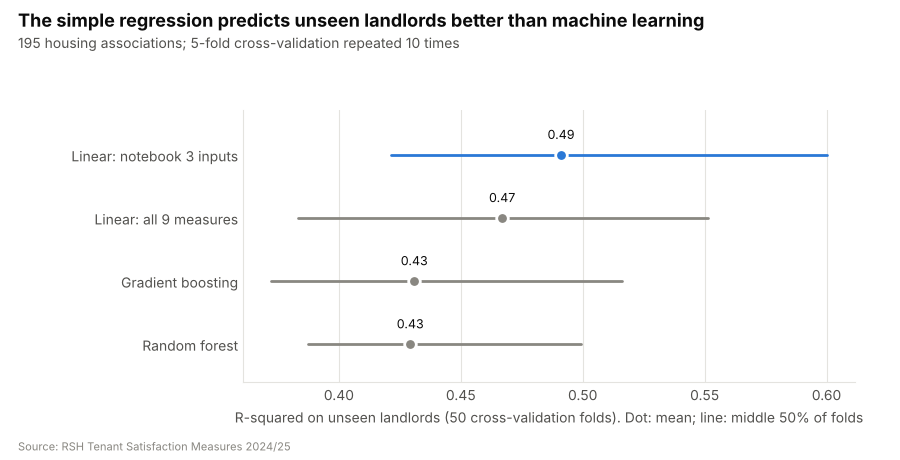

In [11]:
# Models in order of average score, so the best ends up at the top.
order = summary.sort_values("CV R-squared (mean)").index
y_pos = np.arange(len(order))

fig, ax = plt.subplots(figsize=(9, 4.6))
fig.subplots_adjust(left=0.27, right=0.95, top=0.76, bottom=0.17)

# For each model: a line for the middle 50% of its scores, a dot for the average, and the value above it.
for yi, name in zip(y_pos, order):
    folds = scores[name]["r2_folds"]
    colour = HIGHLIGHT if name == "Linear: notebook 3 inputs" else MUTED
    ax.hlines(yi, np.percentile(folds, 25), np.percentile(folds, 75), color=colour, linewidth=2, capstyle="round")
    ax.scatter(folds.mean(), yi, s=70, color=colour, edgecolors=SURFACE, linewidths=2, zorder=3)
    ax.text(folds.mean(), yi + 0.2, f"{folds.mean():.2f}", ha="center", va="bottom", fontsize=9, color=INK)

ax.set_yticks(y_pos, order)
ax.set_ylim(-0.6, len(order) - 0.3)
ax.set_xlabel("R-squared on unseen landlords (50 cross-validation folds). Dot: mean; line: middle 50% of folds")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)

titles(fig, "The simple regression predicts unseen landlords better than machine learning",
       f"{len(data)} housing associations; 5-fold cross-validation repeated 10 times")
fig.savefig("charts/13_model_comparison.png", dpi=200)
plt.show()

### Chart 14: What the random forest relies on

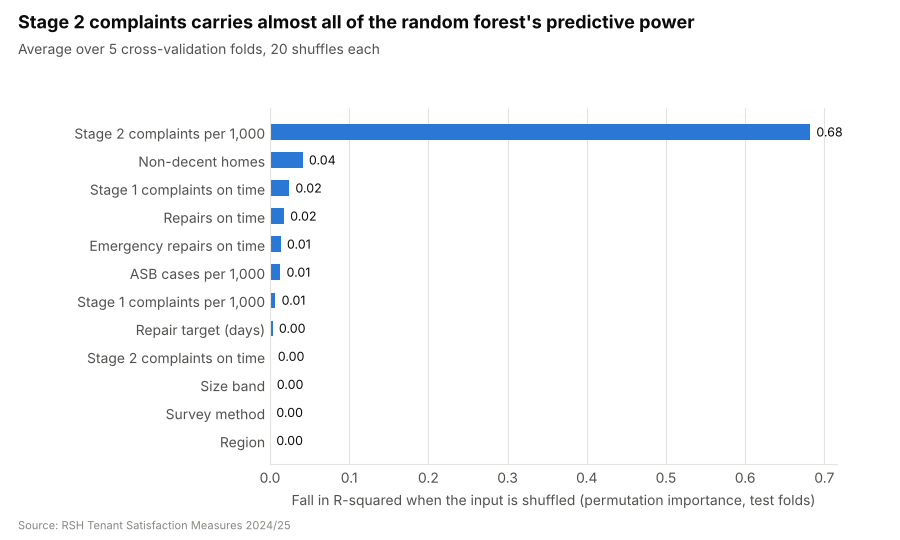

In [12]:
# Readable names for the inputs.
names = {
    "complaints_s2_per_1000": "Stage 2 complaints per 1,000", "non_decent_pc": "Non-decent homes",
    "complaints_s1_on_time_pc": "Stage 1 complaints on time", "repairs_on_time_pc": "Repairs on time",
    "emergency_on_time_pc": "Emergency repairs on time", "asb_per_1000": "ASB cases per 1,000",
    "complaints_s1_per_1000": "Stage 1 complaints per 1,000", "repair_target_days": "Repair target (days)",
    "complaints_s2_on_time_pc": "Stage 2 complaints on time", "size_band": "Size band",
    "method_group": "Survey method", "region": "Region",
}
# barh draws the first item at the bottom, so sorting smallest first puts the biggest at the top.
values = importance.sort_values()
y_pos = np.arange(len(values))

fig, ax = plt.subplots(figsize=(9, 5.4))
fig.subplots_adjust(left=0.30, right=0.93, top=0.80, bottom=0.14)

# One colour for every bar, since it's just one set of numbers. Negative values are shown as zero.
ax.barh(y_pos, values.clip(lower=0).values, height=0.55, color=HIGHLIGHT)
for yi, v in zip(y_pos, values.values):
    # max(v, 0) so tiny negative values show as "0.00" rather than "-0.00".
    ax.text(max(v, 0) + 0.008, yi, f"{max(v, 0):.2f}", va="center", fontsize=9, color=INK)

ax.set_yticks(y_pos, [names[i] for i in values.index])
ax.set_xlabel("Fall in R-squared when the input is shuffled (permutation importance, test folds)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)

titles(fig, "Stage 2 complaints carries almost all of the random forest's predictive power",
       "Average over 5 cross-validation folds, 20 shuffles each")
fig.savefig("charts/14_feature_importance.png", dpi=200)
plt.show()

### Chart 15: Partial dependence

The small ticks along the bottom (a "rug") show where landlords actually sit, which helps show where the curve has plenty of data behind it.

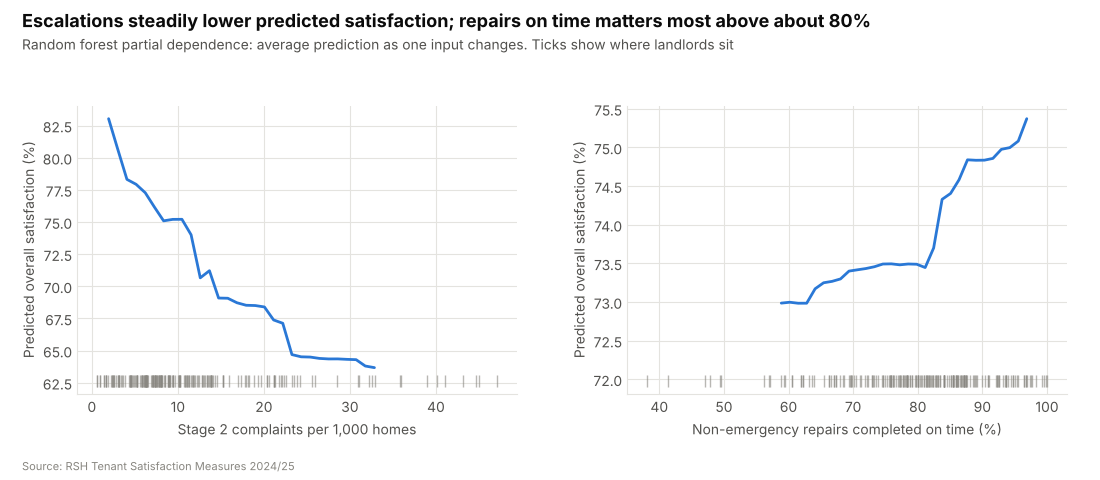

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
fig.subplots_adjust(left=0.07, right=0.97, top=0.78, bottom=0.18, wspace=0.25)

# Each panel: (input, x axis title).
panels = [("complaints_s2_per_1000", "Stage 2 complaints per 1,000 homes"),
          ("repairs_on_time_pc", "Non-emergency repairs completed on time (%)")]
for ax, (col, label) in zip(axes, panels):
    grid, avg = curves[col]
    # The forest's average prediction across the range.
    ax.plot(grid, avg, color=HIGHLIGHT, linewidth=2, solid_capstyle="round")
    # The rug: one small tick per landlord, just below the lowest point of the curve.
    ax.plot(data[col], np.full(len(data), avg.min() - 1), "|", color=MUTED, markersize=8, alpha=0.6)
    ax.set_xlabel(label)
    ax.set_ylabel("Predicted overall satisfaction (%)")

titles(fig, "Escalations steadily lower predicted satisfaction; repairs on time matters most above about 80%",
       "Random forest partial dependence: average prediction as one input changes. Ticks show where landlords sit")
fig.savefig("charts/15_partial_dependence.png", dpi=200)
plt.show()

### Chart 16: Predicted risk against actual satisfaction

Predicted risk across the bottom and actual satisfaction up the side. Landlords below the horizontal line are bottom quartile, and landlords right of the vertical line get flagged. Bottom-quartile landlords are in blue, so the blue dots on the left are the ones the model misses.

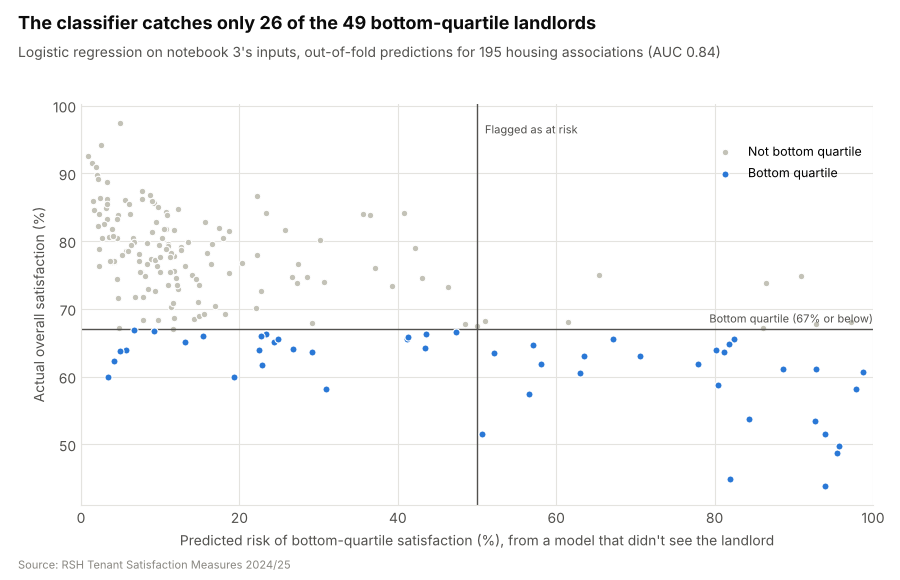

In [14]:
fig, ax = plt.subplots(figsize=(9, 5.8))
fig.subplots_adjust(left=0.09, right=0.97, top=0.82, bottom=0.13)

# Bottom-quartile landlords in blue, everyone else in grey.
bottom = data["bottom_quartile"] == 1
ax.scatter(data.loc[~bottom, "risk"] * 100, data.loc[~bottom, "TP01"], s=22, color=CONTEXT,
           edgecolors=SURFACE, linewidths=0.8, label="Not bottom quartile")
ax.scatter(data.loc[bottom, "risk"] * 100, data.loc[bottom, "TP01"], s=26, color=HIGHLIGHT,
           edgecolors=SURFACE, linewidths=0.8, label="Bottom quartile", zorder=3)
# The bottom-quartile line and the 50% flag line, both labelled.
ax.axhline(threshold, color=INK_2, linewidth=1)
ax.text(100, threshold + 0.6, f"Bottom quartile ({threshold:.0f}% or below)", ha="right", va="bottom", fontsize=8, color=INK_2)
ax.axvline(50, color=INK_2, linewidth=1)
ax.text(51, data["TP01"].max(), "Flagged as at risk", ha="left", va="top", fontsize=8, color=INK_2)

ax.set_xlim(0, 100)
ax.set_xlabel("Predicted risk of bottom-quartile satisfaction (%), from a model that didn't see the landlord")
ax.set_ylabel("Actual overall satisfaction (%)")
ax.legend(loc="upper right", bbox_to_anchor=(1, 0.93), frameon=False, fontsize=9)

titles(fig, f"The classifier catches only {len(caught)} of the {bottom.sum()} bottom-quartile landlords",
       "Logistic regression on notebook 3's inputs, out-of-fold predictions for "
       f"{len(data)} housing associations (AUC {roc_auc_score(data['bottom_quartile'], data['risk']):.2f})")
fig.savefig("charts/16_risk_vs_actual.png", dpi=200)
plt.show()

## What I found

- **The simple regression wins.** Notebook 3's four-input linear regression predicts unseen landlords better (cross-validated R-squared about 0.49) than a random forest or gradient boosting (about 0.43), and better than a linear model with all nine operational measures. With under 200 landlords, the extra flexibility mostly fits noise.
- **The random forest backs up the main finding on its own:** stage 2 complaints carries almost all of its predictive power. Its curves hint that repairs on time might matter most once a landlord gets above about 80%.
- **Bottom-quartile landlords can be flagged well** from operational data (AUC about 0.85), and again the simplest model is as good as the most complex.
- **But the classifier misses about half of them** (23 of 49). Those landlords look fairly ordinary on repairs and complaints, so their satisfaction problem doesn't show up in the operational figures.

**Limitations:**
- **Small data.** 195 housing associations is small for machine learning. With more landlords or more years, the flexible models might do better.
- **Default settings.** I used sensible, cautious settings rather than lots of tuning. Tuning (for example a grid search *inside* cross-validation) might close the gap a bit, but I doubt it would reverse it with this little data.
- **One year.** All of these results are for 2024/25.

**Next:** notebook 9 looks at which of the survey measures matter most to overall satisfaction.